In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

print("pd :", pd.__version__, "| np :", np.__version__, "| sns :", sns.__version__)

pd : 3.1.1 | np : 2.5.5 | sns : 0.13.2


In [4]:
df = sns.load_dataset('titanic')
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [10]:
df.shape
df.info()
df.describe().head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400


In [11]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [12]:
empty_age = df["age"].isnull()
print("나이 빈칸:", empty_age.sum(), "명")
df.loc[empty_age, ["sex", "age", "class"]].head()

나이 빈칸: 177 명


,sex,age,class
5,male,NaN,Third
17,male,NaN,Second
19,female,NaN,Third
26,male,NaN,Third
28,female,NaN,Third


In [16]:
print("평균:",round(df["age"].mean(), 2), "| 중앙값:", df["age"].median())

mean_age = df["age"].mean()
df.loc[:, "age"] = df["age"].fillna(mean_age)
print("남은 빈칸:", df["age"].isnull().sum())
df.loc[empty_age, ["sex", "age", "class"]].head()

평균: 29.7 | 중앙값: 29.69911764705882
남은 빈칸: 0


,sex,age,class
5,male,29.699118,Third
17,male,29.699118,Second
19,female,29.699118,Third
26,male,29.699118,Third
28,female,29.699118,Third


In [18]:
# 사람이 제일 많이 탄 항구 표시 mode()로 최빈값을 목록화하고, [0] 인덱스 0번째, 사우스햄튼으로 채우겠다는 의미

df["embark_town"].value_counts(dropna=False)
mode_town = df["embark_town"].mode()[0]
print("최빈값:", mode_town)
df.loc[:, "embark_town"] = df["embark_town"].fillna(mode_town)
df["embark_town"].value_counts(dropna=False)

최빈값: Southampton


embark_town
Southampton    646
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [19]:
df.loc[:, "embark_town"] = df["embark_town"].str[0]
df[["embarked", "embark_town"]].isnull().sum()

embarked       2
embark_town    0
dtype: int64

In [20]:
test = df["deck"].ffill().bfill()
pd.DataFrame({"원본":df["deck"].value_counts(), "ffill, bfill 후" : test.value_counts() })

,원본,"ffill, bfill 후"
deck,,
A,15,77
B,47,201
C,59,260
D,33,126
E,32,148
F,13,55
G,4,24


In [26]:
print(df["deck"].dtype)
df["deck"].cat.categories

df["deck"] = df["deck"].cat.add_categories("Unknown").fillna("Unknown")
print(df["deck"].cat.categories.tolist())
print(df["deck"].value_counts())
df.isnull().sum().sum()

category
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'Unknown']
deck
Unknown    688
C           59
B           47
D           33
E           32
A           15
F           13
G            4
Name: count, dtype: int64


np.int64(2)

In [29]:
print(df["fare"].quantile([0.25, 0.5, 0.75]))
df["fare"].describe()[["25%", "50%", "75%"]]

q1 = df["fare"].quantile(0.25)
q3 = df["fare"].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}, 위쪽 한계={upper:.2f}")
print("이상치 후보:", (df["fare"] > upper).sum(), "명")
df.loc[df["fare"] > upper, "class"].value_counts()

0.25     7.9104
0.50    14.4542
0.75    31.0000
Name: fare, dtype: float64
Q1=7.91, Q3=31.00, IQR=23.09, 위쪽 한계=65.63
이상치 후보: 116 명


class
First     104
Third       7
Second      5
Name: count, dtype: int64

In [30]:
before = len(df)
df = df[df["fare"] < 300].copy()
print(before, "->", len(df), "명")

891 -> 888 명


In [31]:
print("중복 행:", df.duplicated().sum(), "개")
df[df.duplicated(keep=False)].sort_values(["fare", "age"]).head(6)

중복 행: 107 개


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
277,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True
413,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True
466,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True
481,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True
674,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True
732,0,2,male,29.699118,0,0,0.0,S,Second,man,True,Unknown,S,no,True


In [33]:
t = df.copy()
t["age"][0] = 99
t.loc[0, "age"]

t.loc[0, "age"] = 99
t.loc[0, "age"]

C:\Users\minse\AppData\Local\Temp\ipykernel_2808\503504069.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#chained-assignment
  t["age"][0] = 99


np.float64(99.0)

In [34]:
first = t[t["class"] == "First"]
first.loc [:, "fare"] = 0
print("first 평균:", first["fare"].mean())
print("원본 1등석 평균:", round(t.loc[t["class"] == "First", "fare"].mean(), 2))


first 평균: 0.0
원본 1등석 평균: 78.12


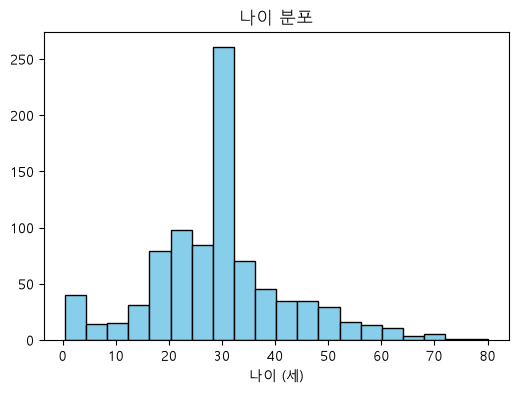

In [36]:
import platform
import matplotlib.pyplot as plt

# 운영체제에 맞는 한글 폰트
os_name = platform.system()
if os_name == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif os_name == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
else:                                    # WSL · Linux · Colab
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지

fig, ax = plt.subplots(figsize=(6, 4))      # 도화지(fig) 1장 + 그래프 칸(ax) 1개
ax.hist(df["age"], bins=20, color="skyblue", edgecolor="black")
ax.set_title("나이 분포")
ax.set_xlabel("나이 (세)")
plt.show()

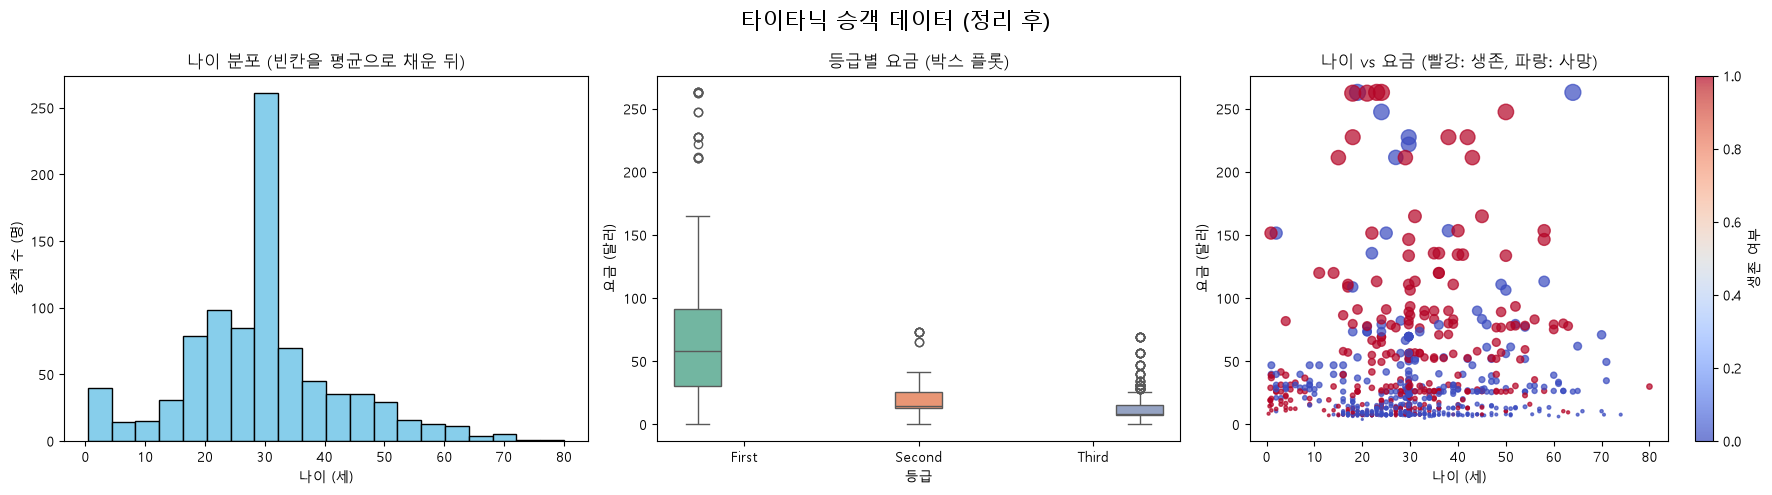

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("타이타닉 승객 데이터 (정리 후)", fontsize=16)

axes[0].hist(df["age"], bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("나이 분포 (빈칸을 평균으로 채운 뒤)")
axes[0].set_xlabel("나이 (세)")
axes[0].set_ylabel("승객 수 (명)")

sns.boxplot(x="class", y="fare", data=df, ax=axes[1], hue="class", palette="Set2", legend=False)
axes[1].set_title("등급별 요금 (박스 플롯)")
axes[1].set_xlabel("등급")
axes[1].set_ylabel("요금 (달러)")

sc = axes[2].scatter(df["age"], df["fare"], c=df["survived"], cmap="coolwarm", s=df["fare"] / 2, alpha=0.7)
axes[2].set_title("나이 vs 요금 (빨강: 생존, 파랑: 사망)")
axes[2].set_xlabel("나이 (세)")
axes[2].set_ylabel("요금 (달러)")
fig.colorbar(sc, ax=axes[2], label="생존 여부")

plt.tight_layout()
plt.show()

In [ ]:
num = df.select_dtypes("number")
print(num.columns.tolist())
num.corr().round(2)

['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.33,-0.07,-0.03,0.08,0.26
pclass,-0.33,1.00,-0.33,0.08,0.02,-0.60
age,-0.07,-0.33,1.00,-0.23,-0.18,0.09
sibsp,-0.03,0.08,-0.23,1.00,0.42,0.21
parch,0.08,0.02,-0.18,0.42,1.00,0.26
fare,0.26,-0.60,0.09,0.21,0.26,1.00


In [ ]:
df.select_dtypes("number").corr()["survived"].round(2)

survived    1.00
pclass     -0.33
age        -0.07
sibsp      -0.03
parch       0.08
fare        0.26
Name: survived, dtype: float64

In [40]:
df.groupby(df["deck"] == "Unknown")["survived"].mean().round(3)

deck
False    0.667
True     0.298
Name: survived, dtype: float64